In [1]:
import numpy as np
import pandas as pd
import cartopy.crs as ccrs
import geopandas as gpd
from shapely.geometry import Polygon, MultiPolygon, Point
from shapely.ops import transform
import cartopy.feature as cfeature
import matplotlib.patheffects as pe
import textwrap
import matplotlib.colors as colors
import matplotlib.pyplot as plt
import xarray as xr
import glob
from tcpyPI import pi

In [2]:
# read in NAtl subbasin polygons
sub_polygons_dict = {}

with open("tc_subbasins_NAtl_v5.dat", "r") as f:
    for line in f:
        line = line.strip()
        if not line or line.startswith("#"):
            continue

        parts = line.split(",")
        sub_basin_name = parts[0].replace('"', '')
        n_vertices = int(parts[1])

        lon_vals = list(map(float, parts[2:2+n_vertices]))
        lon_vals = [(lon + 180) % 360 - 180 for lon in lon_vals]
        lat_vals = list(map(float, parts[2+n_vertices:2+2*n_vertices]))

        coords = list(zip(lon_vals, lat_vals))
        poly = Polygon(coords)

        if sub_basin_name not in sub_polygons_dict:
            sub_polygons_dict[sub_basin_name] = []
        sub_polygons_dict[sub_basin_name].append(poly)

# Convert to GeoDataFrame
sub_basin_records = []

for name, poly_list in sub_polygons_dict.items():
    if len(poly_list) == 1:
        geom = poly_list[0]
    else:
        geom = MultiPolygon(poly_list)

    sub_basin_records.append({
        "sub_basin_name": name,
        "geometry": geom
    })

sub_basins = gpd.GeoDataFrame(sub_basin_records, crs="EPSG:4326",geometry="geometry")

# fix invalid polygons
sub_basins["geometry"] = sub_basins["geometry"].buffer(0)

# remove empty geometries
sub_basins = sub_basins[~sub_basins.geometry.is_empty]

# longitude conversion
import shapely.ops
def shift_lon(geom):
    return shapely.ops.transform(
        lambda x, y: (((x + 180) % 360) - 180, y),
        geom
    )

# shift lon
sub_basins["geometry"] = sub_basins["geometry"].apply(shift_lon)


In [13]:
# load input variables
sst_ds = xr.open_dataset("datasets/potential_intensity/input/sst_mean_1979-2025_daily.nc")
mslp_ds = xr.open_dataset("datasets/potential_intensity/input/mslp_mean_1979-2025_daily_landmasked.nc")
t_ds = xr.open_dataset("datasets/potential_intensity/input/air_temp_mean_1979-2025_daily_landmasked.nc")
r_ds = xr.open_dataset("datasets/potential_intensity/input/mixing_ratio_mean_1979-2025_daily_landmasked.nc")

# DataArrays
sst = sst_ds["sst"]
mslp = mslp_ds["mslp"]
t   = t_ds["air"]
r   = r_ds["__xarray_dataarray_variable__"]

print(r_ds)

<xarray.Dataset> Size: 1GB
Dimensions:                        (time: 7161, p: 17, lat: 37, lon: 57)
Coordinates:
  * time                           (time) datetime64[ns] 57kB 1979-06-01 ... ...
  * p                              (p) float32 68B 1e+03 925.0 ... 20.0 10.0
  * lat                            (lat) float32 148B 90.0 87.5 85.0 ... 2.5 0.0
  * lon                            (lon) float32 228B -120.0 -117.5 ... 20.0
    spatial_ref                    int64 8B ...
    number                         int64 8B ...
    expver                         <U4 16B ...
Data variables:
    __xarray_dataarray_variable__  (time, p, lat, lon) float32 1GB ...


In [14]:
# pressure coordinate
p = t["p"]

# convert temperature from Kelvin to Celsius
t = t - 273.15
t.attrs["units"] = "degC"

# convert mslp from Pa to hPa
mslp = mslp / 100
mslp.attrs["units"] = "hPa"

# interpolate sst grid to match other variable grids (1deg to 2.5deg)
sst = sst.interp(
    lat=t.lat,
    lon=t.lon,
    method="linear"
)

# align datasets
sst, mslp, t, r = xr.align(
    sst,
    mslp,
    t,
    r,
    join="inner"
)

In [15]:
# run pi.py
result = xr.apply_ufunc(
    pi,
    sst,
    mslp,
    p,
    t,
    r,
    kwargs=dict(
        CKCD=0.9,
        ascent_flag=0,
        diss_flag=1,
        ptop=50,
        miss_handle=1,
    ),
    input_core_dims=[
        [],
        [],
        ["p"],
        ["p"],
        ["p"],
    ],
    output_core_dims=[
        [], [], [], [], []
    ],
    output_dtypes=[
        float, float, int, float, float
    ],
    vectorize=True,
    dask="parallelized",
)

vmax, pmin, ifl, t0, otl = result

pi_ds = xr.Dataset(
    {
        "vmax": vmax,
        "pmin": pmin,
        "ifl": ifl,
        "t0": t0,
        "otl": otl,
    }
)

<xarray.Dataset> Size: 19MB
Dimensions:      (time: 222, lat: 37, lon: 57)
Coordinates:
  * time         (time) datetime64[ns] 2kB 1981-09-01 1981-10-01 ... 2025-10-01
  * lat          (lat) float32 148B 90.0 87.5 85.0 82.5 80.0 ... 7.5 5.0 2.5 0.0
  * lon          (lon) float32 228B -120.0 -117.5 -115.0 ... 15.0 17.5 20.0
    spatial_ref  int64 8B 0
    number       int64 8B 0
    expver       <U4 16B '0001'
Data variables:
    vmax         (time, lat, lon) float64 4MB nan nan nan nan ... nan nan nan
    pmin         (time, lat, lon) float64 4MB nan nan nan nan ... nan nan nan
    ifl          (time, lat, lon) int64 4MB 0 0 0 0 0 0 0 0 ... 0 0 0 0 0 0 0 0
    t0           (time, lat, lon) float64 4MB nan nan nan nan ... nan nan nan
    otl          (time, lat, lon) float64 4MB nan nan nan nan ... nan nan nan


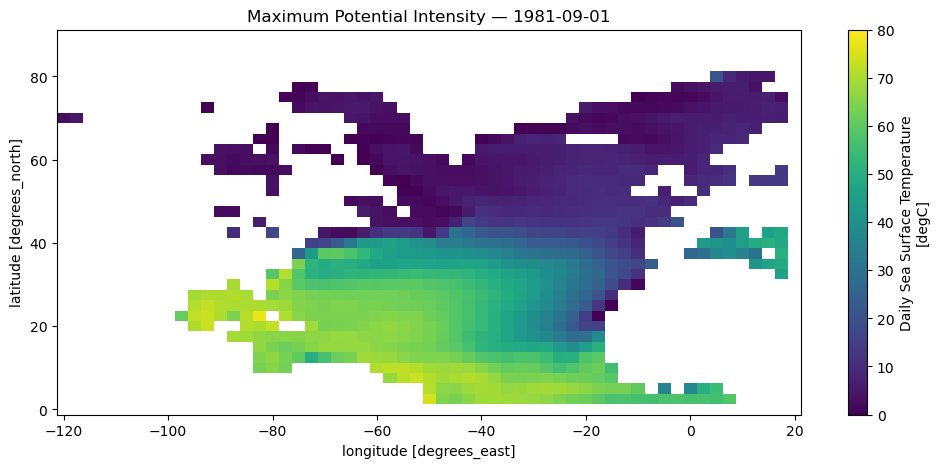

In [16]:
print(pi_ds)

# save to csv
pi_ds.to_netcdf("datasets/potential_intensity/pi_output_daily_landmasked.nc")

# check plot
vmax_mean = vmax.mean(dim="time", skipna=True)
vmax_mean.plot(
    figsize=(12, 5),
    cmap="viridis",
    vmin=0,
    vmax=80
)

plt.title("Maximum Potential Intensity — 1981-09-01")
plt.show()

In [22]:
# get vmax (MPI)
# load PI dataset
ds = xr.open_dataset("datasets/potential_intensity/pi_output_daily_landmasked.nc")

# print(ds)

# convert to data frame
df = ds["vmax"].to_dataframe(name="vmax").reset_index()

# remove missing PI values (over land)
df = df.dropna(subset=["vmax"])

# convert grid cells to points
gdf = gpd.GeoDataFrame(
    df,
    geometry=gpd.points_from_xy(df.lon, df.lat),
    crs="EPSG:4326",
)

# join sub basins
gdf = gpd.sjoin(
    gdf,
    sub_basins[["sub_basin_name", "geometry"]],
    how="inner",
    predicate="within",   # or "intersects"
)

# add year column
gdf['year'] = gdf['time'].dt.year

# pivot to time series
ts = (
    gdf.groupby(["year", "sub_basin_name"])["vmax"]
       .max()
       .reset_index()
)

print(ts)

# save to csv
ts.to_csv("datasets/potential_intensity/vmax_max_perYr_perSb_landmasked.csv")


     year         sub_basin_name       vmax
0    1981                 Arctic  41.038146
1    1981              Caribbean  83.723867
2    1981       Central Atlantic  79.125525
3    1981           Deep Tropics  80.717327
4    1981        Eastern Tropics  95.524410
..    ...                    ...        ...
625  2025  Mid-latitudinal US/CA  16.097478
626  2025  Northeastern Seaboard  73.372234
627  2025        Northern Europe  47.019507
628  2025  Southeastern Seaboard  88.807028
629  2025   Subtropical Atlantic  66.491302

[630 rows x 3 columns]
